# Applied Machine Learning in Healthcare
### Clinical Benchmarks: Fetal State Classification, Metabolic Phenotyping, and Cost Prediction

**Author:** Ipek Kochisarli  
**Repository:** [applied-ml-healthcare](https://github.com/Kochipek/applied-ml-healthcare)

---

## Overview

This notebook provides an end-to-end applied machine learning analysis across three distinct clinical datasets:

1. **Cardiotocography (CTG) Multi-class Classification:** Predicting fetal health status (`Normal`, `Suspect`, `Pathologic`) from 21 fetal heart rate morphological features using Support Vector Machines (SVM) and Random Forest.
2. **Unsupervised Metabolic Phenotyping (Diabetes):** Discovering natural physiological patient clusters in the Pima Indians Diabetes dataset using K-Means, Silhouette analysis, and 2D PCA projection.
3. **Medical Expenditure Regression:** Modeling annual insurance charges with Multiple Linear Regression and Random Forest, capturing non-linear interactions between smoking and obesity.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (confusion_matrix, accuracy_score, silhouette_score,
                             davies_bouldin_score, mean_absolute_error,
                             mean_squared_error, r2_score)

plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

---
## 1. Fetal State Classification (Cardiotocography)

### 1.1 Clinical Context & Problem Definition
Cardiotocography (CTG) is a continuous electronic monitoring technique measuring fetal heart rate (FHR) and uterine contractions during pregnancy and labor. The objective is to identify fetal distress (hypoxia/asphyxia) early to prevent adverse neonatal outcomes.

The dataset from the UCI Machine Learning Repository consists of **2,126 fetal cardiotocograms** with 21 clinical attributes and a 3-class consensus diagnosis target (`NSP`):
- **Normal (1):** Healthy fetus with reassuring physiological markers.
- **Suspect (2):** Borderline indicators requiring close clinical surveillance.
- **Pathologic (3):** Critical fetal distress requiring immediate obstetric intervention.

In [2]:
df_ctg = pd.read_csv("data/cardiotocography.csv")

print(f"Sample count   : {df_ctg.shape[0]}")
print(f"Feature count  : {df_ctg.shape[1] - 1}")
print(f"Missing values : {df_ctg.isnull().sum().sum()}")

class_names = {1: "1 - Normal", 2: "2 - Suspect", 3: "3 - Pathologic"}
print("\nTarget Distribution (NSP):")
print(df_ctg["NSP"].value_counts().sort_index().rename(class_names))
df_ctg.head()

Sample count   : 2126
Feature count  : 21
Missing values : 0

Target Distribution (NSP):
NSP
1 - Normal        1655
2 - Suspect        295
3 - Pathologic     176
Name: count, dtype: int64


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,NSP
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1


### 1.2 Pipeline & Model Training
To prevent data leakage, feature scaling (`StandardScaler`) is encapsulated within `sklearn.pipeline.Pipeline`. Given the clinical class imbalance (only 8.3% Pathologic), `class_weight='balanced'` is utilized to avoid biased majority-class predictions.

In [3]:
X = df_ctg.drop("NSP", axis=1)
y = df_ctg["NSP"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

pipe_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10.0, gamma="scale", class_weight="balanced", random_state=RANDOM_STATE)
)

pipe_rf = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=RANDOM_STATE)
)

pipe_svm.fit(X_train, y_train)
pipe_rf.fit(X_train, y_train)

print(f"Training samples : {X_train.shape[0]}")
print(f"Test samples     : {X_test.shape[0]}")

Training samples : 1700
Test samples     : 426


### 1.3 Evaluation: Confusion Matrices & Per-Class Performance
In medical diagnostics, overall accuracy can be misleading due to class imbalance. We calculate One-vs-Rest **Sensitivity (Recall)** and **Specificity** for each class, prioritizing the detection of Pathologic cases.

SVM Test Accuracy           : 88.73%
Random Forest Test Accuracy : 90.85%

--- SVM Metrics ---
         Class  TP  FP  FN  TN  Sensitivity (%)  Specificity (%)
    Normal (1) 302  11  30  83            90.96            88.30
   Suspect (2)  46  32  13 335            77.97            91.28
Pathologic (3)  30   5   5 386            85.71            98.72

--- Random Forest Metrics ---
         Class  TP  FP  FN  TN  Sensitivity (%)  Specificity (%)
    Normal (1) 313  16  19  78            94.28            82.98
   Suspect (2)  44  20  15 347            74.58            94.55
Pathologic (3)  30   3   5 388            85.71            99.23


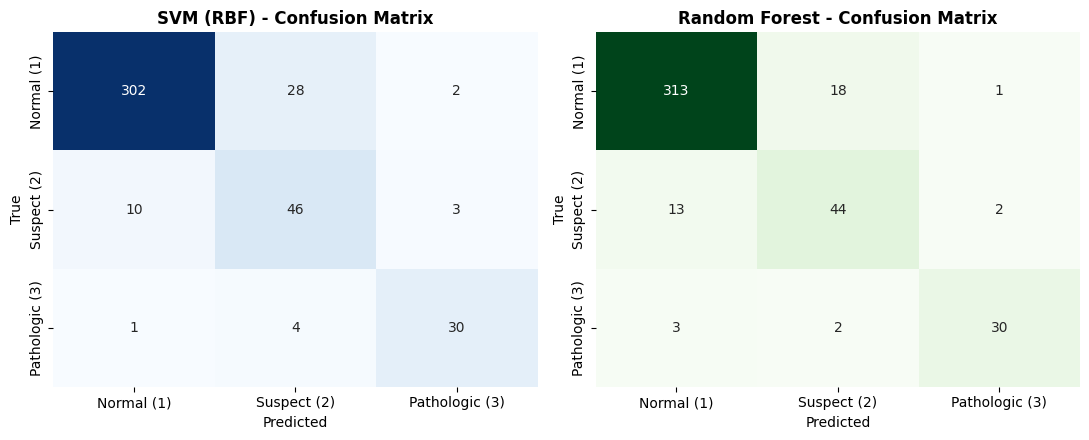

In [4]:
y_pred_svm = pipe_svm.predict(X_test)
y_pred_rf = pipe_rf.predict(X_test)

class_labels = ["Normal (1)", "Suspect (2)", "Pathologic (3)"]

def extract_class_metrics(cm, classes):
    total = np.sum(cm)
    rows = []
    for i, c in enumerate(classes):
        tp = cm[i, i]
        fn = np.sum(cm[i, :]) - tp
        fp = np.sum(cm[:, i]) - tp
        tn = total - (tp + fn + fp)
        sens = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0
        spec = (tn / (tn + fp)) * 100 if (tn + fp) > 0 else 0
        rows.append({
            "Class": c, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "Sensitivity (%)": round(sens, 2),
            "Specificity (%)": round(spec, 2)
        })
    return pd.DataFrame(rows)

cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(f"SVM Test Accuracy           : {accuracy_score(y_test, y_pred_svm)*100:.2f}%")
print(f"Random Forest Test Accuracy : {accuracy_score(y_test, y_pred_rf)*100:.2f}%\n")

print("--- SVM Metrics ---")
print(extract_class_metrics(cm_svm, class_labels).to_string(index=False))
print("\n--- Random Forest Metrics ---")
print(extract_class_metrics(cm_rf, class_labels).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, cm, title, cmap in zip(axes, [cm_svm, cm_rf], ["SVM (RBF) - Confusion Matrix", "Random Forest - Confusion Matrix"], ["Blues", "Greens"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, ax=ax)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.savefig("figures/ctg_confusion_matrices.png", dpi=150)
plt.show()

### 1.4 Feature Importance Analysis
Analyzing the Gini importance from the Random Forest model reveals the decisive clinical biomarkers:

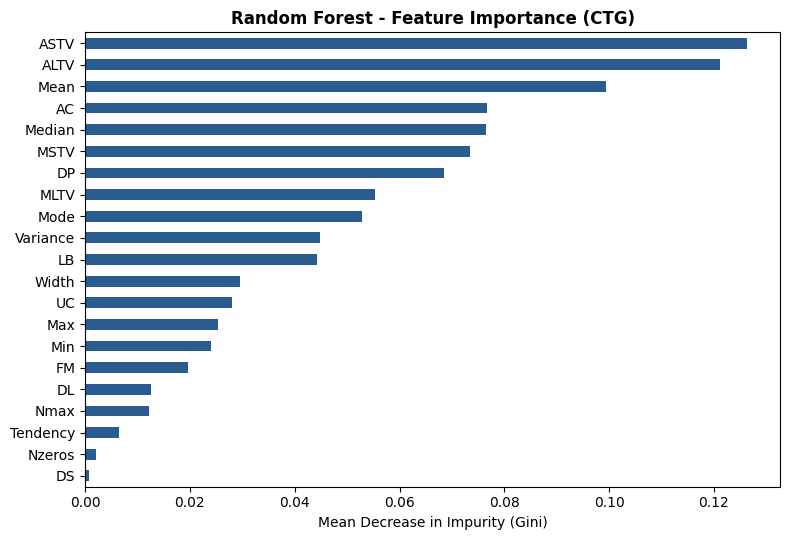

Top 5 Most Informative Features:
ASTV      0.1263
ALTV      0.1211
Mean      0.0995
AC        0.0766
Median    0.0766
dtype: float64


In [5]:
rf_model = pipe_rf.named_steps["randomforestclassifier"]
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5.5))
importance.plot(kind="barh", color="#2b5c8f")
plt.title("Random Forest - Feature Importance (CTG)", fontweight="bold")
plt.xlabel("Mean Decrease in Impurity (Gini)")
plt.tight_layout()
plt.savefig("figures/ctg_feature_importance.png", dpi=150)
plt.show()

print("Top 5 Most Informative Features:")
print(importance.tail(5)[::-1].round(4))

### 1.5 10-Fold Stratified Cross-Validation
To verify that the model generalizes robustly and does not overfit to a single test split, 10-fold stratified cross-validation is performed:

In [6]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_svm = cross_val_score(pipe_svm, X, y, cv=skf, scoring="accuracy")
cv_rf = cross_val_score(pipe_rf, X, y, cv=skf, scoring="accuracy")

cv_table = pd.DataFrame({
    "SVM (RBF)": cv_svm,
    "Random Forest": cv_rf
}, index=[f"Fold {i}" for i in range(1, 11)])

cv_table.loc["Mean"] = cv_table.mean()
cv_table.loc["Std. Dev."] = cv_table.iloc[:10].std(ddof=0)
cv_table.round(4)

,SVM (RBF),Random Forest
Fold 1,0.8967,0.9390
Fold 2,0.8873,0.9484
Fold 3,0.9014,0.9343
Fold 4,0.8873,0.9108
Fold 5,0.9014,0.9343
Fold 6,0.9437,0.9624
Fold 7,0.9104,0.9434
Fold 8,0.9057,0.9434
Fold 9,0.9245,0.9292
Fold 10,0.9245,0.9481


**Clinical Findings:**
- **Pathologic Sensitivity:** Both models achieved **85.71% sensitivity** on the Pathologic class, detecting 30 out of 35 critical cases with high specificity (98.7% - 99.2%).
- **Generalization:** Random Forest achieved **93.93% $\pm$ 1.30%** accuracy across 10 folds, demonstrating high stability.
- **Biomarkers:** Abnormal short-term variability (`ASTV`) and long-term variability (`ALTV`) were the top predictors, which aligns directly with clinical pathophysiology: loss of FHR micro-variability is the primary sign of autonomic hypoxic depression.

---
## 2. Unsupervised Metabolic Phenotyping (Diabetes)

### 2.1 Domain Background & Data Preprocessing
The Pima Indians Diabetes dataset comprises clinical diagnostics for 768 female patients. In clinical records, zero values in physiological parameters such as `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` represent missing data rather than biologically feasible zero measurements. 

These zero values are imputed with non-zero median values, and features are standardized with `StandardScaler`. Diagnosis labels (`Outcome`) are excluded from clustering to ensure pure unsupervised discovery.

In [7]:
df_diab = pd.read_csv("data/diabetes.csv")
features = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
X_d = df_diab[features].copy()

zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zero value counts per physiological feature:")
print((X_d[zero_cols] == 0).sum().to_string())

for col in zero_cols:
    X_d[col] = X_d[col].replace(0, X_d.loc[X_d[col] > 0, col].median())

X_d_scaled = StandardScaler().fit_transform(X_d)

Zero value counts per physiological feature:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11


### 2.2 Optimal Cluster Selection ($k=2..6$)
We evaluate K-Means across cluster counts from $k=2$ to $k=6$ using the **Silhouette Score** (measuring cohesion vs separation) and the **Davies-Bouldin Index** (measuring cluster compactness):

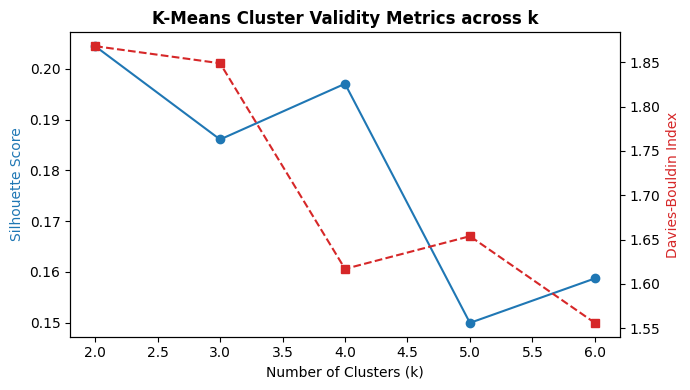

,Silhouette Score,Davies-Bouldin Index
k,,
2,0.2045,1.8681
3,0.1861,1.8489
4,0.1971,1.6168
5,0.1499,1.6537
6,0.1587,1.5559


In [8]:
k_range = range(2, 7)
cluster_metrics = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_d_scaled)
    cluster_metrics.append({
        "k": k,
        "Silhouette Score": silhouette_score(X_d_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_d_scaled, labels)
    })

metrics_df = pd.DataFrame(cluster_metrics).set_index("k")

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(metrics_df.index, metrics_df["Silhouette Score"], "o-", color="#1f77b4")
ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("Silhouette Score", color="#1f77b4")
ax2 = ax1.twinx()
ax2.plot(metrics_df.index, metrics_df["Davies-Bouldin Index"], "s--", color="#d62728")
ax2.set_ylabel("Davies-Bouldin Index", color="#d62728")
plt.title("K-Means Cluster Validity Metrics across k", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/diabetes_clustering_metrics.png", dpi=150)
plt.show()

metrics_df.round(4)

### 2.3 2D PCA Projection & Phenotype Profiles
$k=2$ yields the highest Silhouette Score (0.2045). We project patient records onto the first two principal components to examine cluster separation and examine metabolic phenotypes:

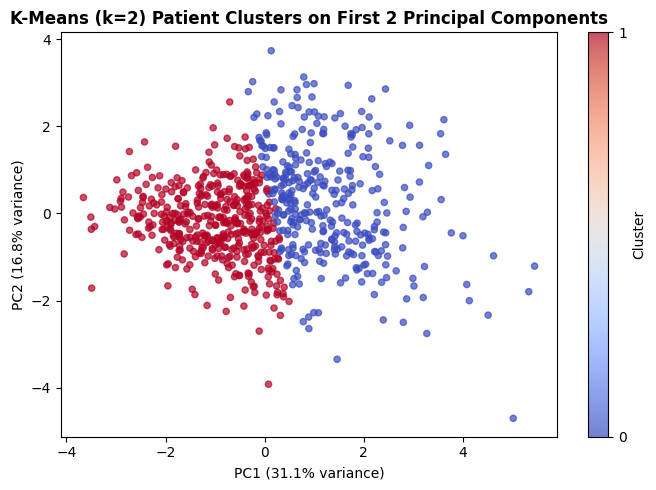

,Glucose,BMI,Age,Insulin,Sample Count,True Diabetes Rate (%)
Cluster,,,,,,
0,140.8,36.0,40.3,108.4,335,56.4
1,105.5,28.9,27.8,57.7,433,18.2


In [9]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
df_diab["Cluster"] = km2.fit_predict(X_d_scaled)

profile = df_diab.groupby("Cluster")[["Glucose", "BMI", "Age", "Insulin"]].mean().round(1)
profile["Sample Count"] = df_diab["Cluster"].value_counts().sort_index()
profile["True Diabetes Rate (%)"] = (df_diab.groupby("Cluster")["Outcome"].mean() * 100).round(1)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_d_scaled)

plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_diab["Cluster"], cmap="coolwarm", s=20, alpha=0.7)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("K-Means (k=2) Patient Clusters on First 2 Principal Components", fontweight="bold")
plt.colorbar(scatter, ticks=[0, 1], label="Cluster")
plt.tight_layout()
plt.savefig("figures/diabetes_pca_clusters.png", dpi=150)
plt.show()

profile

**Clustering Insights:**
- Even though the clustering algorithm operated strictly unsupervised without access to diagnosis labels, post-hoc examination against `Outcome` demonstrates remarkable clinical separation:
  - **Cluster 0 (335 patients):** High-risk metabolic syndrome phenotype (mean Glucose: 140.8 mg/dl, BMI: 36.0, Age: 40.3) with a **56.4% diabetic rate**.
  - **Cluster 1 (433 patients):** Normoglycemic, lower-risk phenotype (mean Glucose: 105.5 mg/dl, BMI: 28.9, Age: 27.8) with an **18.2% diabetic rate**.

---
## 3. Healthcare Expenditure Regression (Medical Cost Personal Datasets)

### 3.1 Problem Definition & Dataset
The Medical Cost Personal Datasets contains 1,338 individual healthcare beneficiaries in the US. The target variable is annual medical insurance charges (`charges` in USD). Features include `age`, `sex`, `bmi`, `children`, `smoker`, and `region`.

In [10]:
df_ins = pd.read_csv("data/insurance.csv")
print(f"Dataset shape: {df_ins.shape}")

df_ins_enc = pd.get_dummies(df_ins, drop_first=True)
X_i = df_ins_enc.drop("charges", axis=1)
y_i = df_ins_enc["charges"]

X_tr_i, X_te_i, y_tr_i, y_te_i = train_test_split(
    X_i, y_i, test_size=0.20, random_state=RANDOM_STATE
)

lr = LinearRegression().fit(X_tr_i, y_tr_i)
rf_reg = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE).fit(X_tr_i, y_tr_i)

predictions = {
    "Multiple Linear Regression": lr.predict(X_te_i),
    "Random Forest Regressor": rf_reg.predict(X_te_i)
}

reg_summary = pd.DataFrame({
    name: {
        "MAE ($)": mean_absolute_error(y_te_i, pred),
        "RMSE ($)": np.sqrt(mean_squared_error(y_te_i, pred)),
        "R²": r2_score(y_te_i, pred)
    }
    for name, pred in predictions.items()
}).T
reg_summary.round(3)

Dataset shape: (1338, 7)


,MAE ($),RMSE ($),R²
Multiple Linear Regression,4181.194,5796.285,0.784
Random Forest Regressor,2550.241,4576.287,0.865


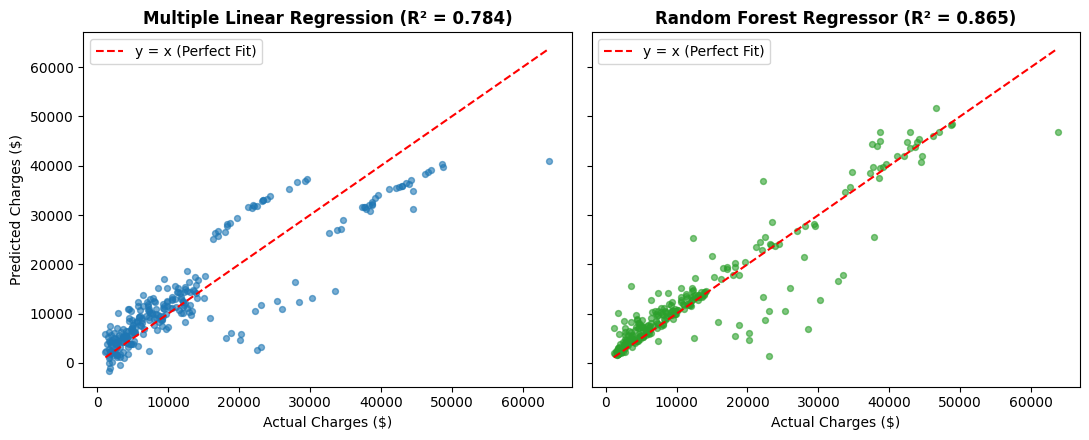

Interaction Effect: Average Annual Charges by Smoking and Obesity (BMI >= 30):
smoker  obese
no      False     7977.03
        True      8842.69
yes     False    21363.22
        True     41557.99
Name: charges, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_te_i, pred, s=18, alpha=0.6, color="#1f77b4" if "Linear" in name else "#2ca02c")
    lims = [y_te_i.min(), y_te_i.max()]
    ax.plot(lims, lims, "r--", lw=1.5, label="y = x (Perfect Fit)")
    ax.set_title(f"{name} (R² = {r2_score(y_te_i, pred):.3f})", fontweight="bold")
    ax.set_xlabel("Actual Charges ($)")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted Charges ($)")
plt.tight_layout()
plt.savefig("figures/medical_cost_regression.png", dpi=150)
plt.show()

print("Interaction Effect: Average Annual Charges by Smoking and Obesity (BMI >= 30):")
print(df_ins.assign(obese=df_ins["bmi"] >= 30).groupby(["smoker", "obese"])["charges"].mean().round(2))

**Regression Insights:**
- **Performance Gap:** Random Forest dramatically outperformed Linear Regression, reducing MAE from $4,181 to **$2,550** (a 39% reduction in average error) and increasing $R^2$ from 0.784 to **0.865**.
- **Non-Linear Compounding Interaction:** In non-smokers, obesity increases average healthcare charges modestly from $7,977 to $8,843 (+$866). However, in smokers, obesity causes expenses to surge from $21,363 to **$41,558** (+$20,195). Linear models fail to capture this multiplicative jump because they assume additive independent feature effects, while tree-based ensembles readily partition multi-dimensional feature spaces.

---

## 4. References

1. **Cardiotocography Data Set**, UCI Machine Learning Repository, Faculty of Medicine and Biomedical Engineering Institute (INEB), University of Porto.
2. **Pima Indians Diabetes Database**, National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK), Kaggle.
3. **Medical Cost Personal Datasets (Insurance Forecast)**, M. Choi, Kaggle.
4. **Scikit-learn: Machine Learning in Python**, Pedregosa et al., JMLR 12, pp. 2825-2830, 2011.